In [23]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline

# Set plot style for better visualization
sns.set_style('whitegrid')
%matplotlib inline

# part 1

# 1. Outlier Detection and Handling

In [24]:
# Load the dataset as a Pandas DataFrame
cal_housing = fetch_california_housing(as_frame=True)
df = cal_housing.frame

# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display the shape of the dataset
print("\nShape of the dataset (rows, columns):")
print(df.shape)

# Display a summary of statistical properties
print("\nSummary of statistical properties:")
display(df.describe())

# Identify feature and target variables
X_raw = df.drop('MedHouseVal', axis=1)
y_raw = df['MedHouseVal']

print(f"\nTarget Variable: 'MedHouseVal'")
print(f"Feature Variables: {list(X_raw.columns)}")

First 5 rows of the dataset:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Shape of the dataset (rows, columns):
(20640, 9)

Summary of statistical properties:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Target Variable: 'MedHouseVal'
Feature Variables: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


# 2. Feature Scaling

In [25]:
# Split the raw dataset into training and testing sets (80/20)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

# Define the models to be trained
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression (d=2)": Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('linreg', LinearRegression())
    ]),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42)
}

# Dictionary to store baseline MSE results
baseline_mse = {}

print("--- Training Baseline Models on Raw Data ---")

# Train models, make predictions, and calculate MSE
for name, model in models.items():
    # Fit the model on the training data
    model.fit(X_train_raw, y_train_raw)
    
    # Make predictions on the test set
    y_pred = model.predict(X_test_raw)
    
    # Calculate and store the Mean Squared Error
    mse = mean_squared_error(y_test_raw, y_pred)
    baseline_mse[name] = mse
    
    print(f"Model: {name}")
    print(f"  Mean Squared Error (MSE): {mse:.4f}\n")

--- Training Baseline Models on Raw Data ---
Model: Linear Regression
  Mean Squared Error (MSE): 0.5559

Model: Polynomial Regression (d=2)
  Mean Squared Error (MSE): 0.4643

Model: Decision Tree
  Mean Squared Error (MSE): 0.4952

Model: Random Forest
  Mean Squared Error (MSE): 0.2554

Model: AdaBoost
  Mean Squared Error (MSE): 0.6145



# part 2

# 1. Outlier Detection and Handling

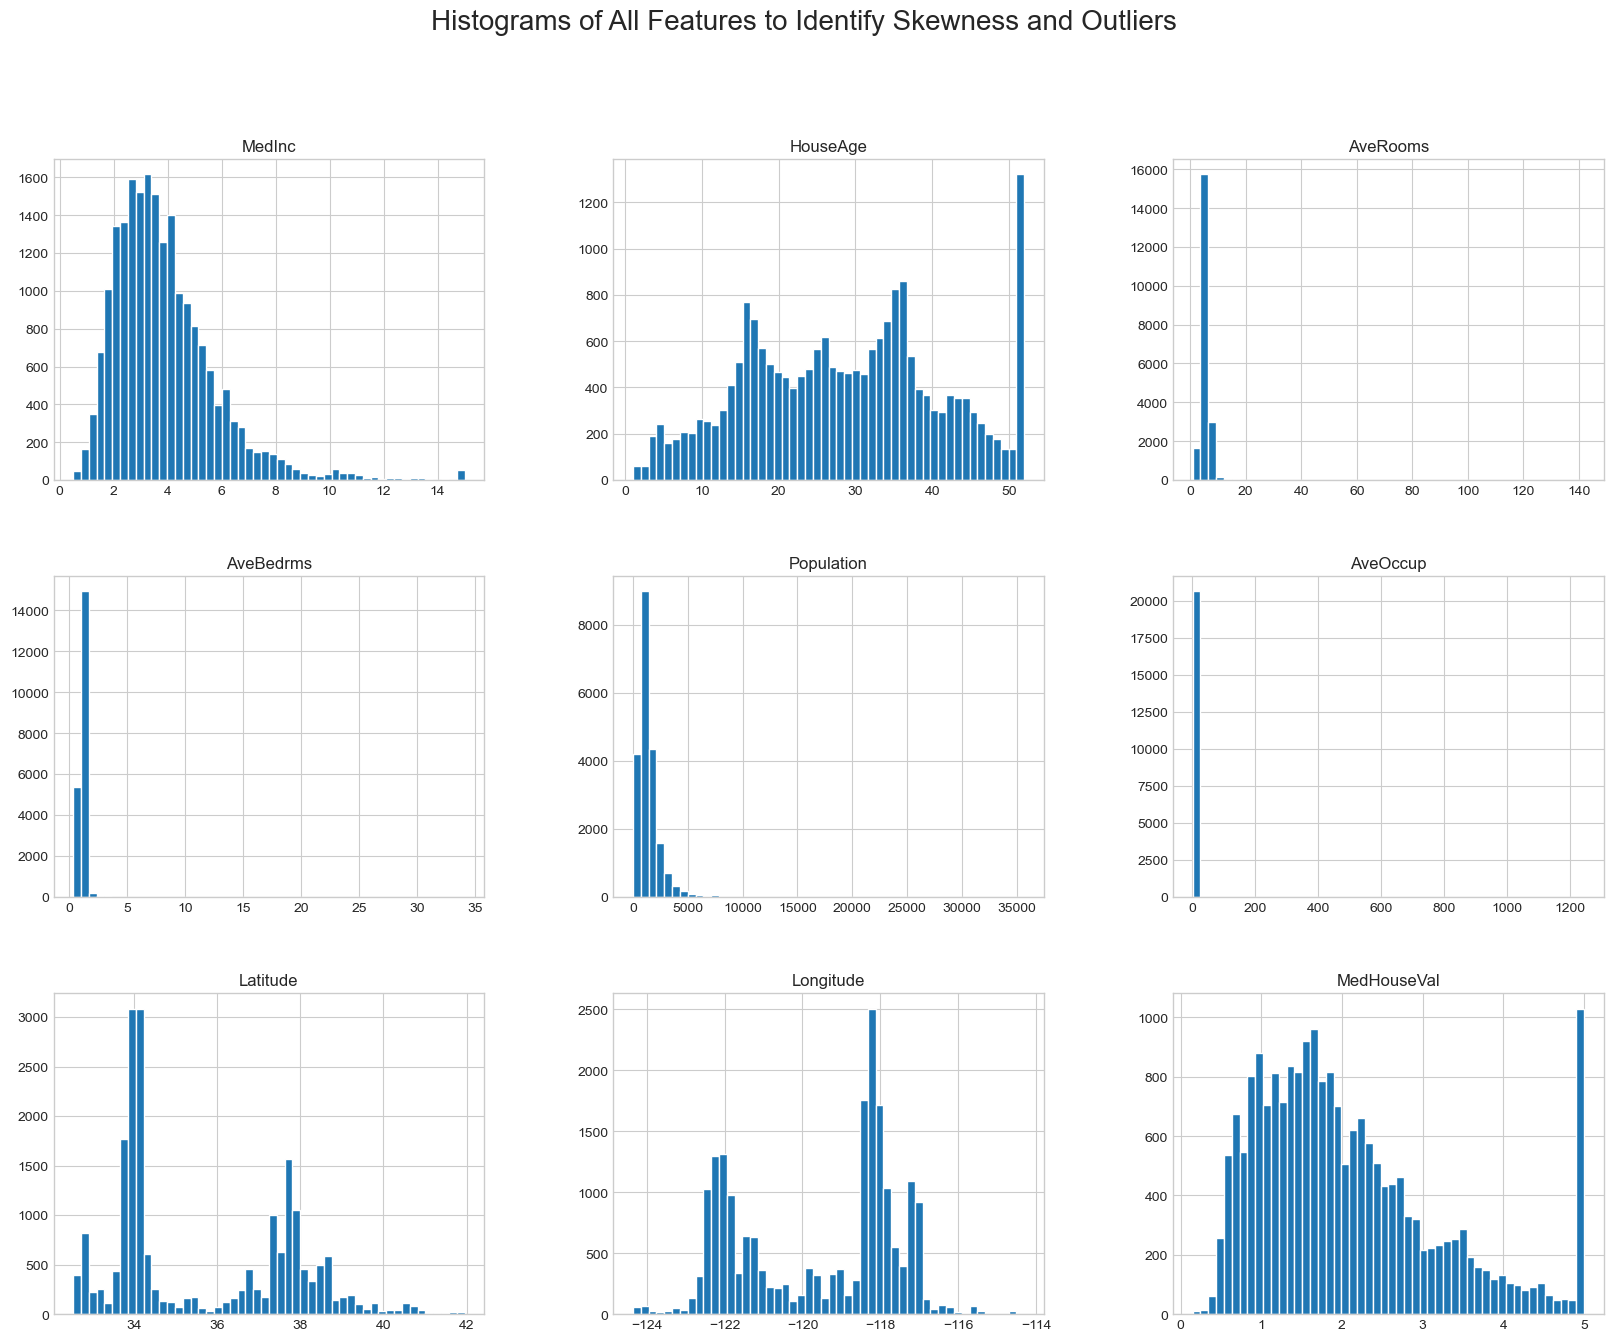

In [26]:
# Plot histograms for all features to identify potential outliers
df.hist(bins=50, figsize=(20, 15))
plt.suptitle("Histograms of All Features to Identify Skewness and Outliers", size=20)
plt.show()

In [27]:
# Create a copy of the dataframe to preprocess
df_processed = df.copy()

print(f"Shape of data before outlier removal: {df_processed.shape}")

# Calculate Q1, Q3, and IQR for each feature
Q1 = df_processed.quantile(0.25)
Q3 = df_processed.quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds and filter the dataframe
outlier_condition = ~((df_processed < (Q1 - 1.5 * IQR)) | (df_processed > (Q3 + 1.5 * IQR))).any(axis=1)
df_processed = df_processed[outlier_condition].reset_index(drop=True)

print(f"Shape of data after outlier removal: {df_processed.shape}")

Shape of data before outlier removal: (20640, 9)
Shape of data after outlier removal: (16312, 9)


# 2. Feature Scaling

In [28]:
# Separate features and target from the cleaned dataset
X_processed = df_processed.drop('MedHouseVal', axis=1)
y_processed = df_processed['MedHouseVal']

# Split the processed data into training and testing sets
X_train_proc, X_test_proc, y_train_proc, y_test_proc = train_test_split(
    X_processed, y_processed, test_size=0.2, random_state=42
)

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler ONLY on the training data to avoid data leakage
scaler.fit(X_train_proc)

# Transform both training and testing data
X_train_scaled = scaler.transform(X_train_proc)
X_test_scaled = scaler.transform(X_test_proc)

print("Feature scaling completed using StandardScaler.")
print(f"Shape of scaled training features: {X_train_scaled.shape}")
print(f"Shape of scaled testing features: {X_test_scaled.shape}")

Feature scaling completed using StandardScaler.
Shape of scaled training features: (13049, 8)
Shape of scaled testing features: (3263, 8)


# part 3

# 1. Final Model Evaluation

In [30]:
# Dictionary to store processed data MSE results
processed_mse = {}

print("--- Training Final Models on Preprocessed Data ---")

# Train models, make predictions, and calculate MSE
for name, model in models.items():
    # Fit the model on the preprocessed training data
    model.fit(X_train_scaled, y_train_proc)
    
    # Make predictions on the preprocessed test set
    y_pred = model.predict(X_test_scaled)
    
    # Calculate and store the Mean Squared Error
    mse = mean_squared_error(y_test_proc, y_pred)
    processed_mse[name] = mse
    
    print(f"Model: {name}")
    print(f"  Mean Squared Error (MSE): {mse:.4f}\n")

--- Training Final Models on Preprocessed Data ---
Model: Linear Regression
  Mean Squared Error (MSE): 0.3165

Model: Polynomial Regression (d=2)
  Mean Squared Error (MSE): 0.2699

Model: Decision Tree
  Mean Squared Error (MSE): 0.4128

Model: Random Forest
  Mean Squared Error (MSE): 0.1785

Model: AdaBoost
  Mean Squared Error (MSE): 0.5357



# 2. Discussion and Comparison

In [32]:
# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Baseline MSE (Raw Data)': baseline_mse,
    'Final MSE (Processed Data)': processed_mse
})

# Calculate the percentage improvement
comparison_df['Improvement (%)'] = 100 * (
    (comparison_df['Baseline MSE (Raw Data)'] - comparison_df['Final MSE (Processed Data)']) / 
    comparison_df['Baseline MSE (Raw Data)']
)

print("--- Model Performance Comparison ---")
display(comparison_df.style.format({
    'Baseline MSE (Raw Data)': '{:.4f}',
    'Final MSE (Processed Data)': '{:.4f}',
    'Improvement (%)': '{:.2f}%'
}).background_gradient(cmap='Greens', subset=['Improvement (%)']))

--- Model Performance Comparison ---


,Baseline MSE (Raw Data),Final MSE (Processed Data),Improvement (%)
Linear Regression,0.5559,0.3165,43.06%
Polynomial Regression (d=2),0.4643,0.2699,41.87%
Decision Tree,0.4952,0.4128,16.64%
Random Forest,0.2554,0.1785,30.11%
AdaBoost,0.6145,0.5357,12.82%


# I have trained the model and then preprocessed it ( applied outlier,then feature scaling so that each feature gets the same weightage from each model and then I have removed the outlier) then I have again trained it and have compared it with the previous models and have gotten improvement in all the models.